In [1]:
import os, importlib, sys, time

In [2]:
import numpy as np
import scipy.sparse as sparse
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow
from tqdm import tqdm

In [3]:
import KECENI

# load data

In [4]:
data_dir = 'data'
save_dir = 'result_delta'

In [5]:
data_network = pd.read_feather('%s/network.feather'%(data_dir))
data_latent = pd.read_feather('%s/latent.feather'%data_dir)

In [6]:
data_network

,row,col
0,1,5
1,1,17
2,2,3
3,2,9
4,3,2
...,...,...
3621,999,837
3622,999,930
3623,999,989
3624,999,993


In [7]:
n_node = len(data_latent); n_node

1000

In [8]:
Adj = sparse.csr_matrix((
    np.full(len(data_network), True), 
    (np.array(data_network.row)-1, np.array(data_network.col)-1)
), shape=(n_node,n_node)).toarray()

In [9]:
G = KECENI.Graph(Adj)

# hyperparameters

In [10]:
from hyperparams import avg_mu, avg_pi, avg, wavg_mu, wavg_pi, wavg, GW, L1

In [11]:
L1_wavg = L1(wavg_mu, wavg_pi, wavg)
L1_avg = L1(avg_mu, avg_pi, avg)

# counterfactual of interest

In [12]:
i0 = 0

In [13]:
T0s_0 = np.full(n_node, 0)
T0s_1 = np.full(n_node, 1)

In [14]:
T0s_0[G.N1(i0)], T0s_1[G.N1(i0)]

(array([0, 0, 0]), array([1, 1, 1]))

In [15]:
i0s = np.array([i0])
T0s = np.array([T0s_0, T0s_1])

# groundtruth

In [16]:
YTR_0, YTR_1 = (-2, 2)
YTR_d = YTR_1 - YTR_0

In [17]:
YTR_0, YTR_1, YTR_d

(-2, 2, 4)

# estimation

In [18]:
n_sim = 80

## - load simulation

In [19]:
lamdas = np.linspace(0, 20, 21)[1:]

In [20]:
YGs_0 = np.zeros(n_sim); YGs_1 = np.zeros(n_sim); YGs_d = np.zeros(n_sim)
YDRs_0_avg = np.zeros(n_sim); YDRs_1_avg = np.zeros(n_sim); YDRs_d_avg = np.zeros(n_sim)
YDRs_0_wavg = np.zeros(n_sim); YDRs_1_wavg = np.zeros(n_sim); YDRs_d_wavg = np.zeros(n_sim)
YDRs_0_GW = np.zeros(n_sim); YDRs_1_GW = np.zeros(n_sim); YDRs_d_GW = np.zeros(n_sim)

In [21]:
for i_sim in tqdm(range(n_sim), desc='sim', total=n_sim):
    locals().update(np.load('%s/result_%.3d.npz'%(save_dir,i_sim)))
    YGs_0[i_sim] = YG_0; YGs_1[i_sim] = YG_1; YGs_d[i_sim] = YG_d
    YDRs_0_avg[i_sim] = YDR_0_avg[id_avg]; YDRs_1_avg[i_sim] = YDR_1_avg[id_avg]; YDRs_d_avg[i_sim] = YDR_d_avg[id_avg]
    YDRs_0_wavg[i_sim] = YDR_0_wavg[id_wavg]; YDRs_1_wavg[i_sim] = YDR_1_wavg[id_wavg]; YDRs_d_wavg[i_sim] = YDR_d_wavg[id_wavg]
    YDRs_0_GW[i_sim] = YDR_0_GW[id_GW]; YDRs_1_GW[i_sim] = YDR_1_GW[id_GW]; YDRs_d_GW[i_sim] = YDR_d_GW[id_GW]

sim: 100%|██████████| 80/80 [00:12<00:00,  6.26it/s]


## - G estimate

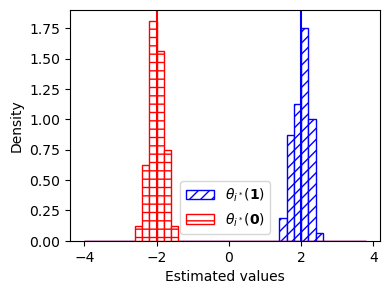

In [22]:
fig = plt.figure(figsize=(4,3))
plt.hist(YGs_1, density=True, bins=np.arange(-4,4,0.2), 
         facecolor='white', edgecolor='blue', hatch="///", 
         label=r'$\theta_{i^*}(\mathbf{1})$')
plt.axvline(YTR_1, color='blue')
plt.hist(YGs_0, density=True, bins=np.arange(-4,4,0.2), 
         facecolor='white', edgecolor='red', hatch="--",
         label=r'$\theta_{i^*}(\mathbf{0})$')
plt.axvline(YTR_0, color='red')
plt.xlabel('Estimated values'); plt.ylabel('Density'); plt.legend()

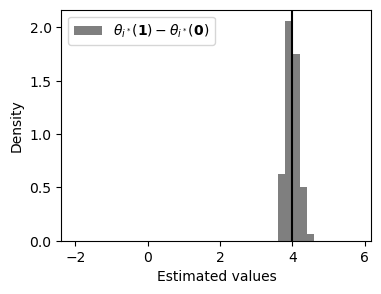

In [23]:
fig = plt.figure(figsize=(4,3))
plt.hist(YGs_d, color='black', alpha=0.5, density=True, bins=np.arange(-2,6,0.2),
         label=r'$\theta_{i^*}(\mathbf{1}) - \theta_{i^*}(\mathbf{0})$')
plt.axvline(YTR_d, color='black')
plt.xlabel('Estimated values'); plt.ylabel('Density'); plt.legend()

In [24]:
np.sqrt(np.mean((YGs_d - YTR_d)**2, 0))

0.17607422473390827

## - KECENI

In [25]:
YDRs_0 = np.stack([YDRs_0_avg, YDRs_0_wavg, YDRs_0_GW], 0)
YDRs_1 = np.stack([YDRs_1_avg, YDRs_1_wavg, YDRs_1_GW], 0)
YDRs_d = np.stack([YDRs_d_avg, YDRs_d_wavg, YDRs_d_GW], 0)

In [26]:
kernels = ['Correct Mapping', 'Incorrect Mapping', 'GW']

In [27]:
from matplotlib import cm

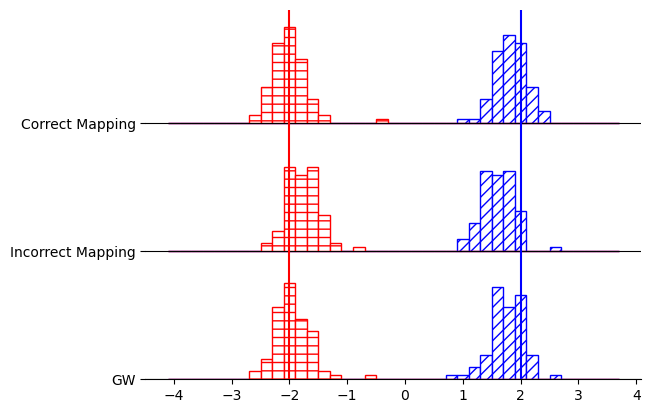

In [28]:
ax = plt.gca()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(True)
ax.spines['left'].set_visible(False)
ax.set_yticks(-2*np.arange(len(kernels)), ['%s' % k for k in kernels])

for i in np.arange(len(kernels)):
    freq_G1, bin_G1 = np.histogram(YDRs_1[i], density=True, bins=np.arange(-4,4,0.2))
    plt.bar(bin_G1[:-1], freq_G1, width=np.diff(bin_G1), 
            bottom=-2*i, zorder=2*i,
            facecolor='white', edgecolor='blue', hatch="///")
    # plt.axhline(y=-2*i, color=cm.Blues(0.5+0.1*i), zorder=2*i+1)
    
    freq_G2, bin_G2 = np.histogram(YDRs_0[i], density=True, bins=np.arange(-4,4,0.2))
    plt.bar(bin_G2[:-1], freq_G2, width=np.diff(bin_G2), 
            bottom=-2*i, zorder=2*i,
            facecolor='white', edgecolor='red', hatch="--")
    
    plt.axhline(y=-2*i, color='black', linewidth=0.8, zorder=2*i+1)
    
plt.axvline(x=YTR_1, color='blue', zorder=12)
plt.axvline(x=YTR_0, color='red', zorder=12)
    
plt.show()

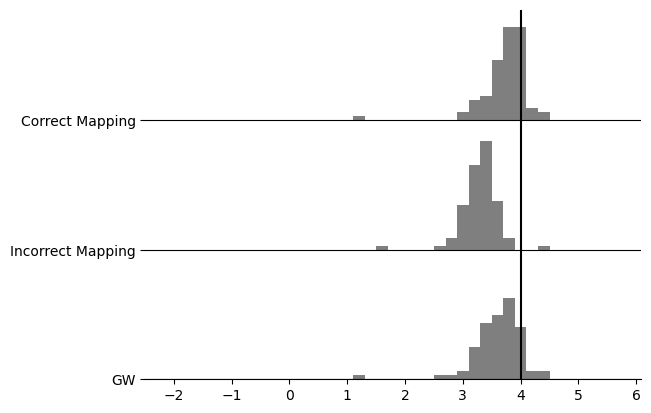

In [29]:
ax = plt.gca()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(True)
ax.spines['left'].set_visible(False)
ax.set_yticks(-2*np.arange(len(kernels)), ['%s' % k for k in kernels])

for i in np.arange(len(kernels)):
    freq_Gd, bin_Gd = np.histogram(YDRs_d[i], density=True, bins=np.arange(-2,6,0.2))
    plt.bar(bin_Gd[:-1], freq_Gd, width=np.diff(bin_Gd), 
            bottom=-2*i, zorder=2*i,
            color='black', alpha=0.5)
    
    plt.axhline(y=-2*i, color='black', linewidth=0.8, zorder=2*i+1)
    
plt.axvline(x=YTR_d, color='black', zorder=12)
    
plt.show()

In [30]:
np.sqrt(np.mean((YDRs_1 - YTR_1)**2, -1))

array([0.28072291, 0.39864   , 0.31572052])

In [31]:
np.sqrt(np.mean((YDRs_0 - YTR_0)**2, -1))

array([0.32766502, 0.42043296, 0.35484454])

In [32]:
np.sqrt(np.mean((YDRs_d - YTR_d)**2, -1))

array([0.4270149 , 0.69535847, 0.50971191])